# plot_01c. ERA5: evaluation maps (figures)

Drawn from what calc_03a and calc_03b saved, so nothing slow runs. Section 7 places ERA5 among each model's members at every grid point (the moment test, as plot_01b does at the point) and asks, with the field test, whether ERA5 is flagged over more of the map than a perfect model would be. Section 8 draws calc_03b's spatial evaluation.

Sections 1 to 6 are in plot_01a and plot_01b, and the observed change in plot_01d.

## Setup

In [1]:
import sys
sys.path[:0] = ['..']   # this repository: the extant package and plotting_modules

import logging
import warnings
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from plotting_modules.constants import SEASONS
from extant import era5_evaluation as ev
from extant.config import VARIABLES
from extant.datatree import tree_to_dataset
from extant.logger import setup_logging
from extant.plots import antarctica, era5_evaluation as evp, forced_response as fr
from extant.plots import response_change as rcp

logger = setup_logging('extant', logging.INFO)
xr.set_options(display_expand_attrs=False, display_expand_data=False)

#(t): Harmless warnings, silenced the same way in every notebook. zarr's, that parts of the stores (the text
#(t): coordinates, the consolidated metadata) aren't in the Zarr 3 standard yet:
warnings.filterwarnings('ignore', message='.*Zarr (format 3|V3) specification')
#(t): numpy's, about slices with nothing but NaN (land, a model without a member) or nothing at all, too few members for
#(t): a standard deviation, and dividing by zero or by NaN (the log of a probability of 0, say):
warnings.filterwarnings('ignore', message='All-NaN slice encountered', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Mean of empty slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Degrees of freedom <= 0 for slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='(divide by zero|invalid value) encountered', category=RuntimeWarning)
#(t): dask's, about large task graphs, which are large on purpose:
warnings.filterwarnings('ignore', message='.*Sending large graph of size', category=UserWarning)
#(t): Every figure's text at the notebook's sizes and colours (fr.NOTEBOOK), as in every notebook
plt.rcParams.update(fr.NOTEBOOK.rc)

In [2]:
%matplotlib inline

## Settings

In [3]:
#(t): As in calc_03a and calc_03b: the variable (its name and units)
VARIABLE = VARIABLES['tas']

#(t): The model of the one-model figures
EXAMPLE_MODEL = 'CanESM5'

In [4]:
#(t): Where calc_03a to calc_03c saved their results: JASMIN's scratch
SCRATCH_DIR = Path('/work/scratch-pw4/aborow/ExtAnt')
SCRATCH_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt')

## Which Results

Run **one** of the next two sections: each sets the folder the results are opened from, the sample's or the full data's.

### Sample data

In [5]:
#(t): The sample's results
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'sample'
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/sample')

### Full data

In [6]:
#(t): The full data's results
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'full'
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full')

## Open the Results

First what calc_03a to calc_03c saved in `RESULTS_DIR`, then each result opened.

In [7]:
#(t): What calc_03a to calc_03c saved in RESULTS_DIR
RESULTS_DIR, sorted(path.name for path in RESULTS_DIR.glob('*.zarr'))

(PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full'),
 ['anomaly_ranks.zarr',
  'demo_anomaly_ranks.zarr',
  'demo_detrended_ranks.zarr',
  'demo_plume.zarr',
  'demo_statistics.zarr',
  'demo_tests.zarr',
  'detections.zarr',
  'detrended_ranks.zarr',
  'era5_kurtosis.zarr',
  'era5_lower_tail.zarr',
  'era5_mean.zarr',
  'era5_point.zarr',
  'era5_regional.zarr',
  'era5_regional_trend.zarr',
  'era5_skewness.zarr',
  'era5_std.zarr',
  'era5_trend.zarr',
  'era5_upper_tail.zarr',
  'era5_width.zarr',
  'eval_map_table.zarr',
  'eval_table.zarr',
  'experiment_noise.zarr',
  'final_mean.zarr',
  'final_quantiles.zarr',
  'first_look.zarr',
  'forced.zarr',
  'hist_nat_final_quantiles.zarr',
  'histnat_point.zarr',
  'historical_kurtosis.zarr',
  'historical_lower_tail.zarr',
  'historical_mean.zarr',
  'historical_point.zarr',
  'historical_skewness.zarr',
  'historical_std.zarr',
  'historical_trend.zarr',
  'historical_upper_tail.zarr',
  'historical_width.zarr',
  'mean_

In [ ]:
#(t): Every statistic notebook calc_03a saved, in one store, each a variable named after it: every member's in
#(t): /<model>/historical (on member, season, lat, lon), ERA5's in /ERA5 (on season, lat, lon)
statistics_path = RESULTS_DIR / 'statistics.zarr'
statistics_path

In [ ]:
statistics_tree = xr.open_datatree(statistics_path, engine='zarr').load()

In [ ]:
#(t): The models' members, /<model>/historical
historical_statistics_tree = statistics_tree.match('*/historical')

In [ ]:
#(t): ... and ERA5's
era5_statistics_ds = statistics_tree['ERA5'].to_dataset().load()

In [30]:
#(t): The spatial evaluation (calc_03b)
spatial_table_ds = xr.open_zarr(RESULTS_DIR / 'spatial_table.zarr').load()

## 7. Moment Test Maps

The moment test at every grid point of every model: `ev.locate` on calc_03a's maps, point by point, as at the point. Then the **field test** (`ev.field_test`): a perfect model is flagged at about 10% of grid points by chance, and neighbouring points are correlated, so the question is whether ERA5 is flagged over *more* of the map than a perfect model would be. Each member in turn plays ERA5 against the other N − 1, and the areas they are flagged over show what a perfect model gives (Livezey & Chen, 1983, with the members as the null). It is gone through step by step below, on EXAMPLE_MODEL's standard deviation.

In the maps: ERA5's percentile among each model's members, darkest where it is beyond their 5–95%. Top left of each panel, the field test: the % of the map where ERA5 is flagged, and the most a perfect model gives 90% of the time; ✗ when ERA5 is flagged over more. Models with fewer than 20 members cannot flag anything and are left blank.

In [ ]:
#(t): The moment test's four statistics
moment_statistics = ['mean', 'std', 'skewness', 'kurtosis']

In [ ]:
#(t): The four moments at every grid point: where ERA5's falls among each model's members, point by point
#(t): (ev.locate), along a statistic dim, on (statistic, member, season, lat, lon)
moment_map_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node.to_dataset()[moment_statistics].to_dataarray('statistic'),
                         era5_statistics_ds[moment_statistics].to_dataarray('statistic'))
    for node in historical_statistics_tree.leaves
})

**How `ev.field_test` works**, step by step on EXAMPLE_MODEL's map of the standard deviation, in DJF. A perfect model is flagged at about 10% of the grid points by chance, so a map of flags cannot say on its own whether the model fails: the field test asks whether ERA5 is flagged over more of the map than the members are, each member playing ERA5 against the others.

In [ ]:
#(t): EXAMPLE_MODEL's standard deviation test at every grid point (moment_map_test_tree, above): ERA5's among the
#(t): members', point by point
field_std_ds = moment_map_test_tree[EXAMPLE_MODEL]['historical'].to_dataset().sel(statistic='std', drop=True)

In [104]:
#(t): At each grid point, how many members there are and how many ERA5's is greater than
field_n_da = field_std_ds['members'].notnull().sum('member')
field_less_da = (field_std_ds['members'] < field_std_ds['era5']).sum('member')

In [105]:
#(t): ERA5 tested against N - 1 members, as each pseudo-observation is: the share of the N leave-one-out tests that flag it
# Example: 50 members, and ERA5 greater than 48 of them.
# Leave out one of those 48 (48 of the 50 ways): ERA5 is greater than 47 of the 49 others and 2 are greater than it, so
# p = 2 * (2 + 1) / 50 = 0.12, which is not less than 0.1: not flagged.
# Leave out one of the other 2 (2 of the 50 ways): ERA5 is greater than 48 of the 49 and 1 is greater than it, so
# p = 2 * (1 + 1) / 50 = 0.08: flagged. ERA5 is flagged in 2 of the 50 tests, so this point is given 2 / 50 = 0.04.
# ev._flagged applies ev.locate's p-value rule to a count of the others less than it.
field_era5_flagged_da = ((field_less_da / field_n_da) * ev._flagged(field_less_da - 1, field_n_da - 1, ev.ALPHA)
                         + ((field_n_da - field_less_da) / field_n_da)
                         * ev._flagged(field_less_da, field_n_da - 1, ev.ALPHA))

In [106]:
#(t): Each member as a pseudo-observation: how many of the other N - 1 members it is greater than (ev._rank_among_others),
#(t): and whether that is flagged by the same rule
field_pseudo_less_da = xr.apply_ufunc(ev._rank_among_others, field_std_ds['members'], input_core_dims=[['member']],
                                      output_core_dims=[['member']])
field_pseudo_flagged_da = ev._flagged(field_pseudo_less_da, field_n_da - 1, ev.ALPHA)

In [107]:
#(t): The % of the map flagged (cos-latitude weighted), for ERA5 and for each pseudo-observation
# Only the grid points where a pseudo-observation can be flagged at all count: 2 / N less than 0.1, more than 20 members.
field_present_da = field_std_ds['era5'].notnull() & (2 / field_n_da < ev.ALPHA)
field_weights_da = np.cos(np.deg2rad(field_std_ds['lat']))
field_era5_area_da = 100 * field_era5_flagged_da.astype(float).where(field_present_da).weighted(
    field_weights_da).mean(['lat', 'lon'])
field_pseudo_area_da = 100 * field_pseudo_flagged_da.astype(float).where(field_present_da).weighted(
    field_weights_da).mean(['lat', 'lon'])

In [108]:
#(t): The field p-value: the share of the pseudo-observations flagged over at least as much of the map as ERA5, with ERA5
#(t): counted as one more
# Example: 50 pseudo-observations, 3 of them flagged over at least as much of the map as ERA5: p = (3 + 1) / (50 + 1) = 0.078.
# That is less than 0.1, so ERA5 is flagged over more of the map than a perfect model would be: the model fails.
field_pvalue_da = (((field_pseudo_area_da >= field_era5_area_da).sum('member') + 1)
                   / (field_pseudo_area_da.notnull().sum('member') + 1))

In [109]:
#(t): Check: the steps against ev.field_test (largest difference of the field p-value: 0)
field_check_ds = ev.field_test(field_std_ds)
float(abs(field_pvalue_da - field_check_ds['field_pvalue']).max())

0.0

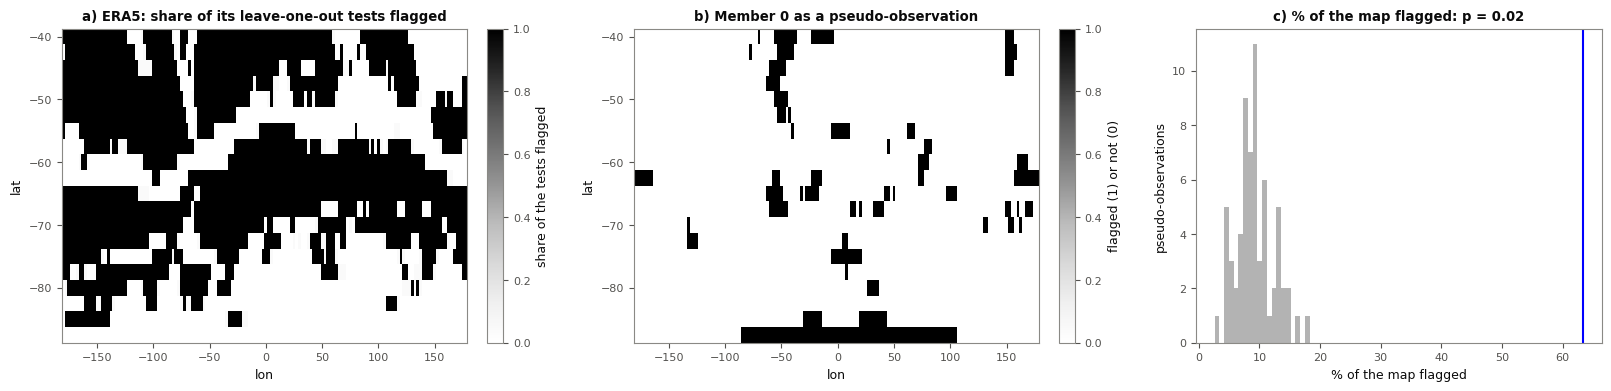

In [110]:
#(t): ev.field_test step by step on EXAMPLE_MODEL's standard deviation in DJF: a) the share of ERA5's leave-one-out tests that
#(t): flag it at each point; b) member 0 as a pseudo-observation, flagged (1) or not (0); c) the % of the map flagged,
#(t): every pseudo-observation (grey) and ERA5 (blue)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), layout='constrained')
field_era5_flagged_da.sel(season='DJF').plot(ax=axes[0], x='lon', y='lat', cmap='Greys', vmin=0, vmax=1,
                                             cbar_kwargs={'label': 'share of the tests flagged'})
axes[0].set_title("a) ERA5: share of its leave-one-out tests flagged")
field_pseudo_flagged_da.isel(member=0).sel(season='DJF').astype(float).plot(ax=axes[1], x='lon', y='lat', cmap='Greys',
                                                                            vmin=0, vmax=1,
                                                                            cbar_kwargs={'label': 'flagged (1) or not (0)'})
axes[1].set_title('b) Member 0 as a pseudo-observation')
field_pseudo_area_da.sel(season='DJF').plot.hist(ax=axes[2], bins=20, color='0.7')
axes[2].axvline(float(field_era5_area_da.sel(season='DJF')), color='blue')
axes[2].set(title=f"c) % of the map flagged: p = {float(field_pvalue_da.sel(season='DJF')):.2f}",
            xlabel='% of the map flagged', ylabel='pseudo-observations');

In [111]:
#(t): The field test of every model, moment and season (ev.field_test), merged with the tests at every grid point, and
#(t): without the members
map_test_tree = xr.DataTree.from_dict({
    node.path: xr.merge([node.to_dataset(), ev.field_test(node.to_dataset())]).drop_dims('member')
    for node in moment_map_test_tree.leaves
})

In [112]:
#(t): Every model in one Dataset, on (model, statistic, season, lat, lon)
eval_map_table_by_experiment_ds = tree_to_dataset(map_test_tree, dims=['model', 'experiment'], coords='minimal',
                                                  compat='override')
eval_map_table_ds = eval_map_table_by_experiment_ds.sel(experiment='historical', drop=True)
eval_map_table_ds

<xarray.Dataset> Size: 18MB
Dimensions:        (model: 6, statistic: 4, lat: 20, lon: 144, season: 4)
Coordinates:
  * model          (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon            (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * season         (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat            (lat) float64 160B -87.5 -85.0 -82.5 ... -45.0 -42.5 -40.0
  * statistic      (statistic) <U8 128B 'mean' 'std' 'skewness' 'kurtosis'
Data variables:
    era5           (statistic, lat, lon, season, model) float64 2MB -29.67 .....
    lower          (statistic, lat, lon, season, model) float64 2MB -25.96 .....
    median         (statistic, lat, lon, season, model) float64 2MB -25.62 .....
    upper          (statistic, lat, lon, season, model) float64 2MB -25.33 .....
    percentile     (statistic, lat, lon, season, model) float64 2MB 0.0 ... 3...
    pvalue         (statistic, lat, lon, season, model) float64 2MB 0.0303 .....
    verdict        (statistic, lat, lon, season, model) float64 2MB -1.0 ... 0.0
    testable       (statistic, lat, lon, season, model) float64 2MB 1.0 ... 1.0
    flagged_area   (statistic, season, model) float64 768B 85.54 15.43 ... 7.355
    perfect_area   (statistic, season, model) float64 768B 19.36 20.5 ... 12.14
    field_pvalue   (statistic, season, model) float64 768B 0.01515 ... 0.7955
    field_verdict  (statistic, season, model) float64 768B 1.0 0.0 ... 0.0 0.0

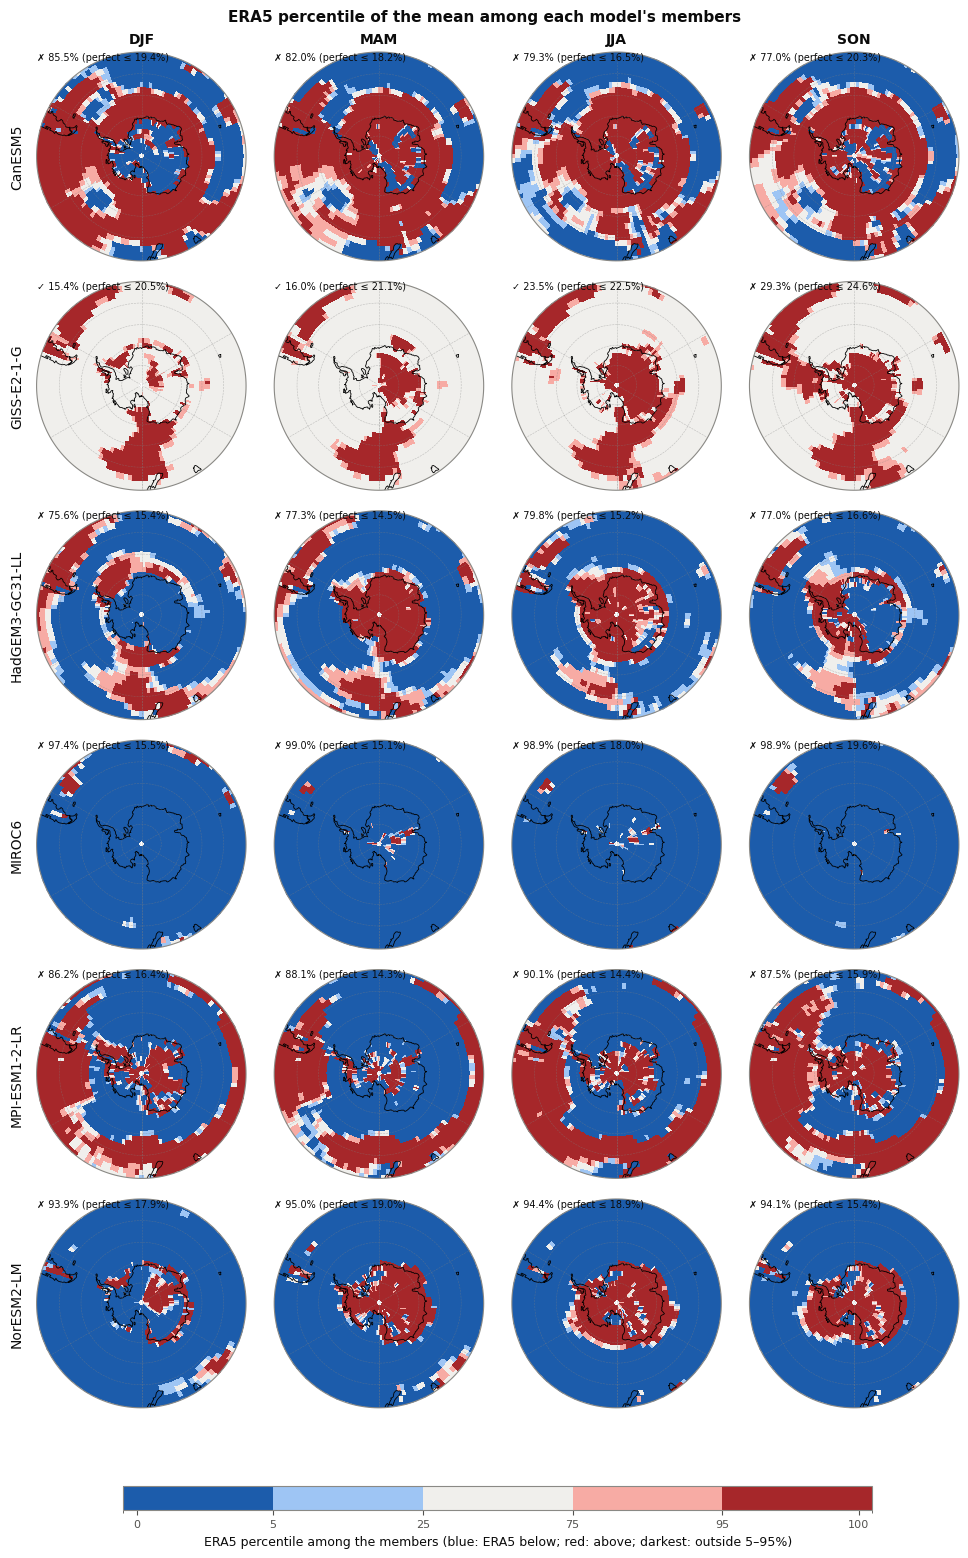

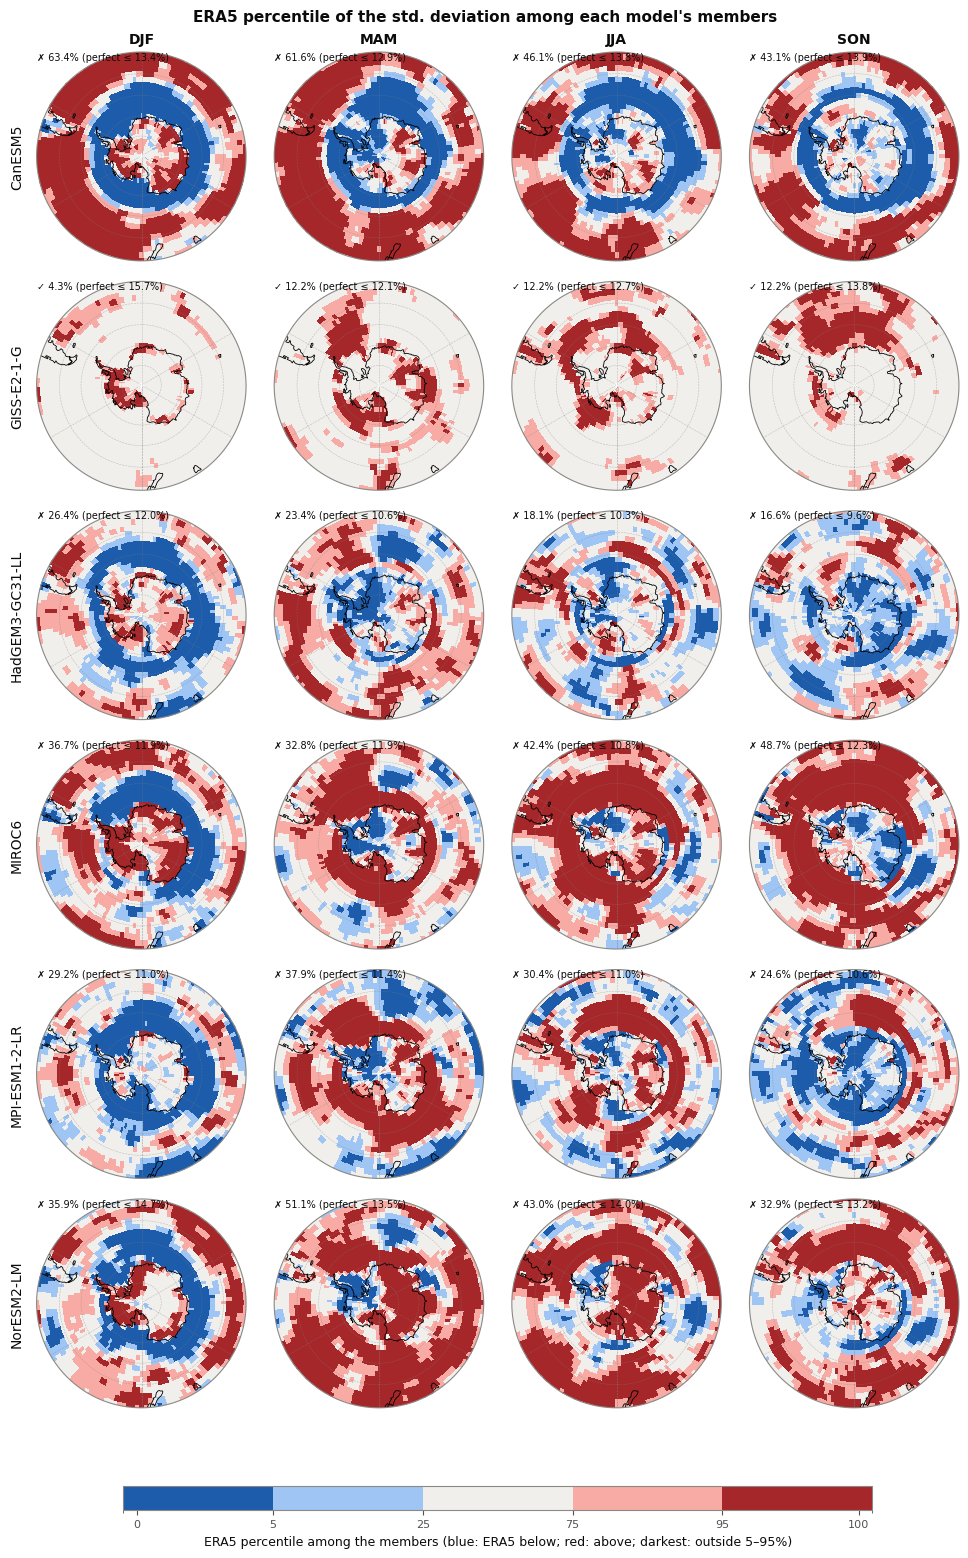

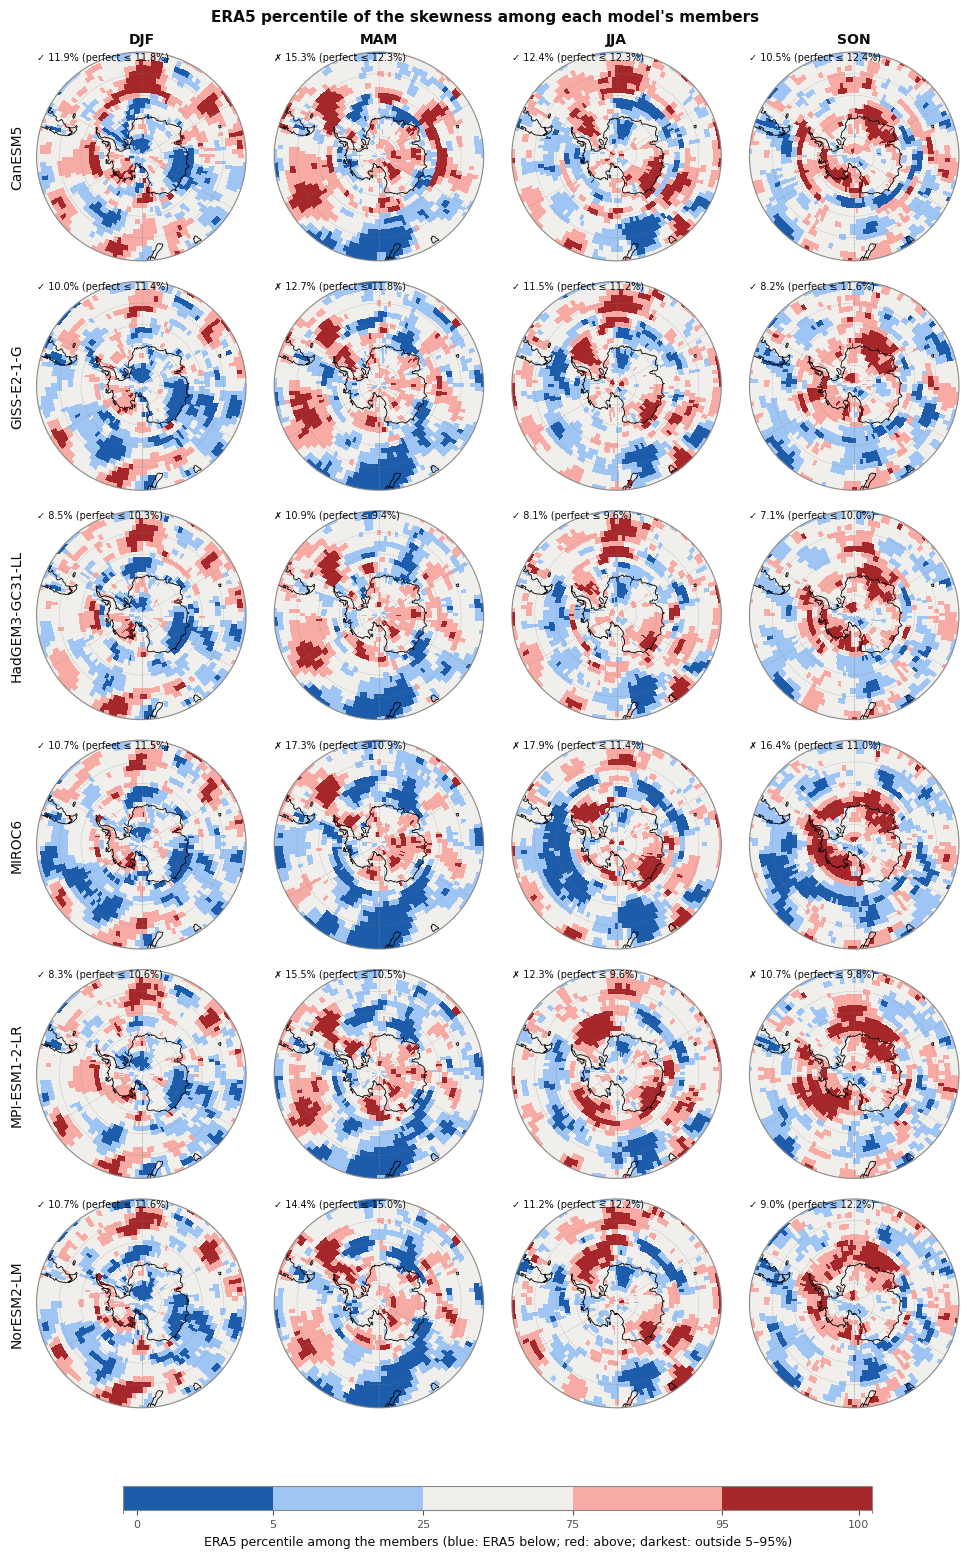

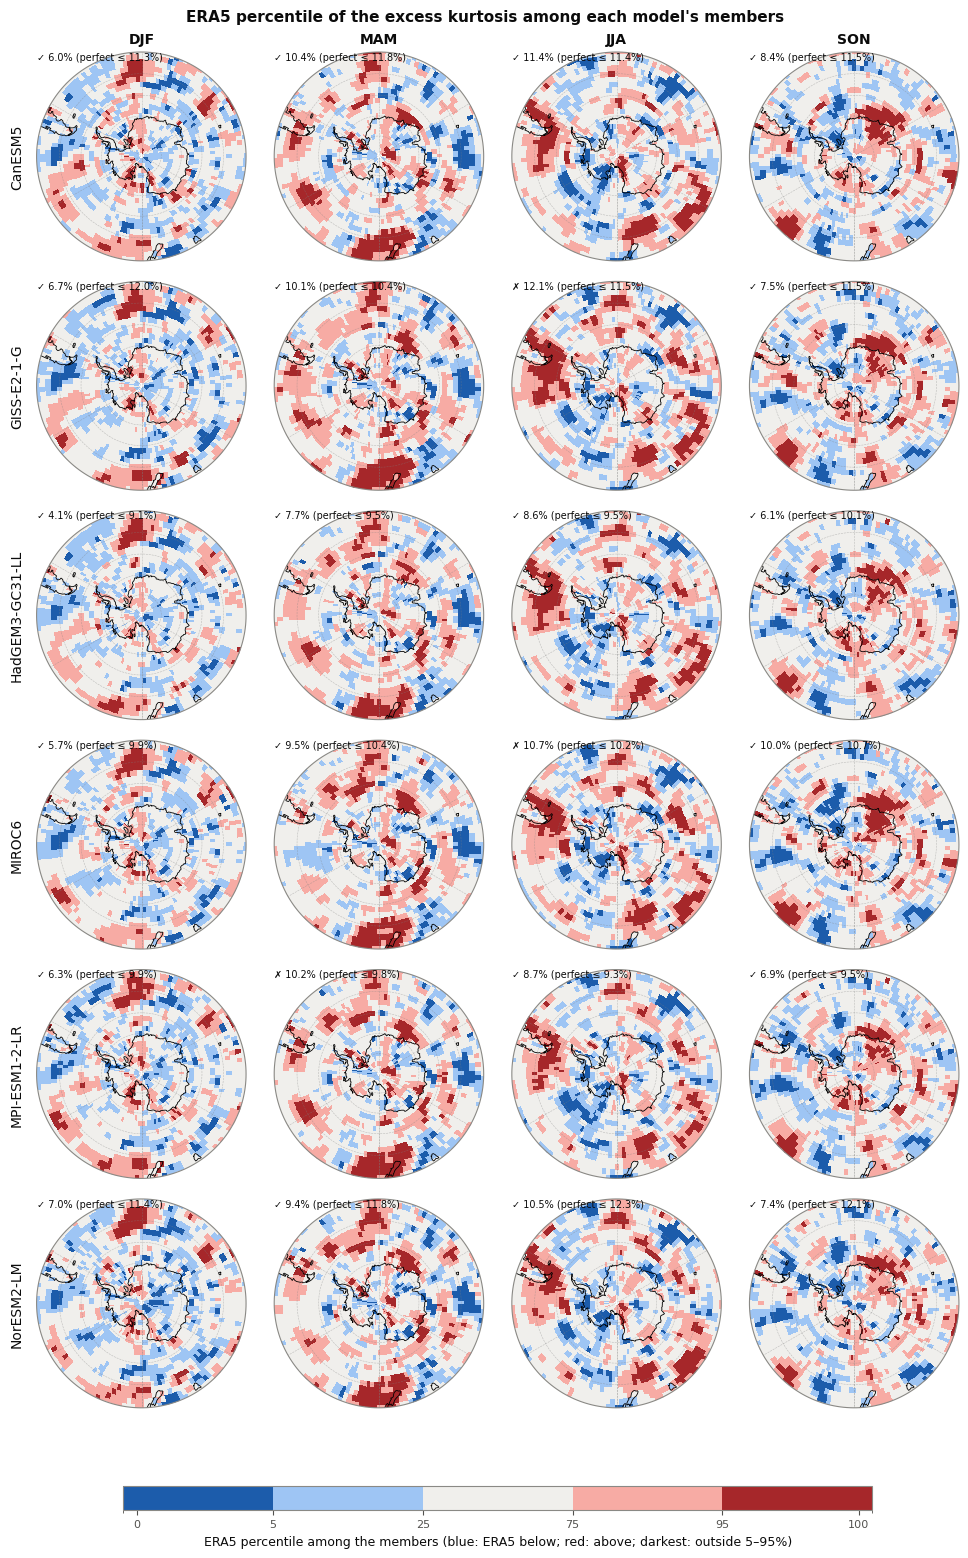

In [113]:
#(t): ERA5's percentile among each model's members (rows), every season, one figure per statistic: blank where a model
#(t): has too few members to test; in each map's corner the field test, ✓ if ERA5 is flagged over no more of the map
#(t): than a perfect model's pseudo-observations would be, ✗ if over more
percentile_cmap, _ = evp.percentile_colormap()
for statistic in ['mean', 'std', 'skewness', 'kurtosis']:
    statistic_ds = eval_map_table_ds.sel(statistic=statistic, season=SEASONS)
    #(c): Blank where too few members can flag anything: a dark class there would mean nothing
    percentile_da = statistic_ds['percentile'].where(statistic_ds['testable'] == 1)
    models = percentile_da['model'].values
    fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=len(models), n_cols=len(SEASONS), n_colorbar_rows=1),
                     layout='constrained')
    axes = antarctica.map_axes(fig, n_rows=len(models), n_cols=len(SEASONS))
    cax = antarctica.colorbar_axis_below(axes)

    antarctica.heatmaps_of_antarctica(percentile_da, 'model', 'season', axes=axes, cax=cax,
                                      levels=evp.PERCENTILE_EDGES, cmap=percentile_cmap, extend='neither',
                                      ticks=evp.PERCENTILE_BOUNDS,
                                      label='ERA5 percentile among the members (blue: ERA5 below; red: above; darkest: '
                                            'outside 5–95%)')
    #(c): Each map's note: too few members to test, or the field test's verdict
    for i, model in enumerate(models):
        for j, season in enumerate(SEASONS):
            map_ds = statistic_ds.sel(model=model, season=season)
            if bool(percentile_da.sel(model=model, season=season).isnull().all()):
                axes[i, j].text(0.5, 0.5, 'too few members\nto test (N < 20)', transform=axes[i, j].transAxes,
                                ha='center', va='center', fontsize=8)
            elif 'field_verdict' in map_ds and bool(map_ds['field_verdict'].notnull()):
                mark = '✓' if int(map_ds['field_verdict']) == 0 else '✗'
                axes[i, j].text(0.0, 1.0, f"{mark} {float(map_ds['flagged_area']):.1f}% (perfect ≤ "
                                          f"{float(map_ds['perfect_area']):.1f}%)",
                                transform=axes[i, j].transAxes, ha='left', va='top', fontsize=7)

    antarctica.label_columns(axes, SEASONS)
    antarctica.label_rows(axes, models)
    fig.suptitle(f"ERA5 percentile of the {evp.statistic_label(eval_map_table_ds, statistic).lower()} among each "
                 f"model's members")

TypeError: Plotting requires coordinates to be numeric, boolean, or dates of type numpy.datetime64, datetime.datetime, cftime.datetime or pandas.Interval. Received data of type object instead.

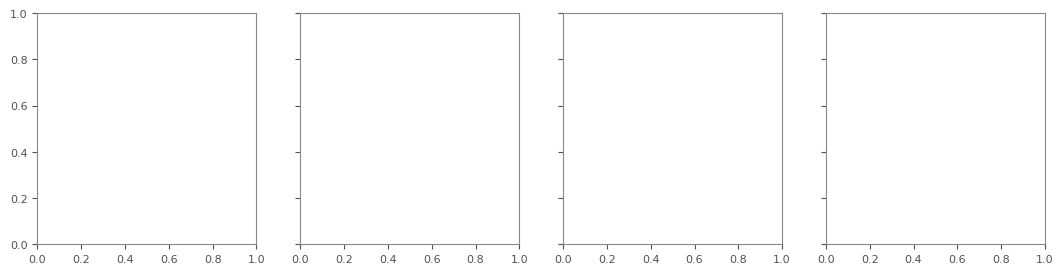

In [114]:
#(t): The field test for every model, moment and season: 1 (✗) where ERA5 is flagged over more of the map than a
#(t): perfect model gives, 0 (✓) where not, blank with too few members
#(c): The model names are Python objects after tree_to_dataset; xarray only puts strings on an axis
field_verdict_da = eval_map_table_ds['field_verdict'].sel(season=SEASONS)
field_verdict_da = field_verdict_da.assign_coords(model=field_verdict_da['model'].astype(str))
fg = field_verdict_da.plot(x='season', y='model', col='statistic', vmin=0, vmax=1, cmap='Reds', add_colorbar=False)

In [ ]:
#(t): How many models are consistent with ERA5 (ERA5 inside their members' 5-95%) at each grid point
#(c): Only models with enough members to be tested (N >= 20) are counted, as consistent or not
testable_da = eval_map_table_ds['testable'] == 1
n_eval_models = int(testable_da.any([dim for dim in testable_da.dims if dim != 'model']).sum())
count_cmap, _ = rcp.count_colormap(n_eval_models, base_cmap='Blues')
n_consistent_da = ((eval_map_table_ds['verdict'] == 0) & testable_da).sum('model')
statistics = n_consistent_da['statistic'].values

#(c): Every statistic (rows) and season, one colour bar: white for none, a darker blue for each model more
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=len(statistics), n_cols=len(SEASONS), n_colorbar_rows=1),
                 layout='constrained')
axes = antarctica.map_axes(fig, n_rows=len(statistics), n_cols=len(SEASONS))
cax = antarctica.colorbar_axis_below(axes)
antarctica.heatmaps_of_antarctica(n_consistent_da.sel(season=SEASONS), 'statistic', 'season', axes=axes,
                                  cax=cax, levels=np.arange(-0.5, n_eval_models + 1.5), cmap=count_cmap,
                                  extend='neither', ticks=range(n_eval_models + 1),
                                  label="Models with ERA5 inside their members' 5-95% range")
antarctica.label_columns(axes, SEASONS)
antarctica.label_rows(axes, [ev.MOMENTS[statistic].label for statistic in statistics])
fig.suptitle('Number of models consistent with ERA5');

## 8. Spatial Evaluation (Suarez-Gutierrez et al., 2021)

The paper's grid-point evaluation (their sections 2.2.2 and 3.2–3.4), at every grid point and season. It does not use the members-as-observations rank histograms of plot_01b's section 5 (the paper keeps those for the global mean). Instead it reduces each point's rank histogram to three numbers and compares them with what a perfect model gives, using fixed thresholds (`ev.spatial_evaluation`):

1. **Anomalies.** Every member and ERA5 minus its own mean over 1979–2013, so a constant offset is gone and the forced change and the variability are left. (The paper uses 1961–1990, which is before ERA5 starts.)
2. **Years.** Only years ERA5 has; a point with fewer than 10 is not tested.
3. **Rank.** Each year, is ERA5 below every member (rank 0), above every member (rank N), or in between?
4. **Three percentages.** The % of years below every member, above every member, and inside the members' central 75% (12.5–87.5%).
5. **Against a perfect model.** If ERA5 were one more member, it would be below every member in 100 / (N + 1) % of years (2% for 50 members), above in as many, and in the central 75% about 75% of the time. Short records push these up by chance, so the paper flags only **≥ 10% below**, **≥ 10% above** or **> 80% in the middle**. Models with N < 20 are not tested with these thresholds: 10 members already put ERA5 beyond them 9% of the time on each side. `SPATIAL_THRESHOLDS = 'perfect_model'` (not in the paper) sets the thresholds from the members instead: each member in turn is treated as ERA5 against the other N − 1, and a percentage counts as a problem above the 95th percentile of theirs. That works for any N.
6. **Diagnosis**, using when the edge years fall (1979–1996 or 1997–2013):

| ERA5 is … | Diagnosis |
|---|---|
| below the members mostly late, or above them mostly early | the model **warms too much** (forced response too strong) |
| above the members mostly late, or below them mostly early | the model **warms too little** |
| both below and above, throughout | **too little variability**: the spread is too narrow |
| in the central 75% more than 80% of the time | **too much variability**: the spread is too wide |
| beyond one edge only, throughout | **one tail too short**: the shape of the distribution |
| none of these | **adequate** |

   The sign flips with time because anomalies are taken over the whole record: a model that warms too fast looks too cold early and too warm late, relative to ERA5. With both edges beyond 10%, both must point the same way to count as the forced response.
7. **Early against late.** A model's variability changes little over time, but the forcing does. So each problem over the whole record is checked for an uneven split between 1979–1996 and 1997–2013 (a binomial test, p < 0.1). Spread evenly, it is the **variability**; concentrated in one period, or flipping between them, the **forced response**. Each half is only ~17 years per season, too short to compare its own flags directly, which in 17 years would flag even a perfect model's middle about a third of the time.
8. **Score.** The adequate share of the tested area per model (each panel's corner), and how many models are adequate at each grid point (the paper's Fig. 8).

In [ ]:
#(t): The spatial evaluation in the order of the seasons, and its models: the rows of the maps below
spatial_seasons_ds = spatial_table_ds.sel(season=SEASONS)
models = spatial_seasons_ds['model'].values

In [ ]:
#(t): The paper's Fig. 5: ERA5 above (red) or below (blue) every member in at least 10% (light) or 20% (dark) of years,
#(t): purple both; hatched where ERA5 is in the members' central 75% too often (> ev.CENTRAL_THRESHOLD = 80% of years
#(t): ////, > 90% xxxx). The classes' names on two lines ('above\n≥ 10%'), so they fit under the bar
edge_names = [name.replace(' ≥', '\n≥') for name in evp.EDGE_CLASSES]
#(c): The classes' colour bar under the maps, then the hatching's legend
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=len(models), n_cols=len(SEASONS), n_colorbar_rows=1,
                                                    n_legends=1, colorbar_height=1.0), layout='constrained')
axes = antarctica.map_axes(fig, n_rows=len(models), n_cols=len(SEASONS))
cax = antarctica.colorbar_axis_below(axes)

antarctica.heatmaps_of_antarctica(evp.edge_class(spatial_seasons_ds), 'model', 'season', axes=axes, cax=cax,
                                  levels=np.arange(-0.5, len(edge_names)), cmap=ListedColormap(evp.EDGE_COLORS),
                                  extend='neither', ticks=range(len(edge_names)), ticklabels=edge_names,
                                  label='% of years ERA5 is above (red) or below (blue) every member')
antarctica.hatching_grid(spatial_seasons_ds['central'] > ev.CENTRAL_THRESHOLD, 'model', 'season', axes=axes,
                         pattern='////')
antarctica.hatching_grid(spatial_seasons_ds['central'] > 90, 'model', 'season', axes=axes, pattern='xxxx')
#(c): Each map's note: not tested, or the share of the map where the model is adequate
for i, model in enumerate(models):
    for j, season in enumerate(SEASONS):
        map_ds = spatial_seasons_ds.sel(model=model, season=season)
        if bool(map_ds['adequate'].isnull().all()):
            axes[i, j].text(0.5, 0.5, f'not tested\n(N < {ev.MIN_MEMBERS} or < {ev.MIN_YEARS} years)',
                            transform=axes[i, j].transAxes, ha='center', va='center', fontsize=8)
        else:
            axes[i, j].text(0.0, 1.0, f'adequate {float(ev.adequate_area(map_ds)):.0f}%', transform=axes[i, j].transAxes,
                            ha='left', va='top', fontsize=7.5)

antarctica.label_columns(axes, SEASONS)
antarctica.label_rows(axes, models)
#(c): The hatching's legend, under the colour bar
fig.legend(handles=[Patch(facecolor='white', edgecolor='0.35', hatch='////',
                          label=f"ERA5 in the members' central 75% in > {ev.CENTRAL_THRESHOLD}% of years"),
                    Patch(facecolor='white', edgecolor='0.35', hatch='xxxx', label='... in > 90% of years')],
           loc='outside lower center', ncols=2, frameon=False, fontsize=9)
fig.suptitle('Where ERA5 is beyond the ensemble, or too often in its middle');

In [ ]:
#(t): What is wrong at each grid point (step 6)
#(c): The classes' names on lines of up to 12 characters, so they fit under the bar, which gets the room for them
class_names = [textwrap.fill(name, 12) for name in ev.DIAGNOSES.values()]
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=len(models), n_cols=len(SEASONS), n_colorbar_rows=1,
                                                    colorbar_height=1.0), layout='constrained')
axes = antarctica.map_axes(fig, n_rows=len(models), n_cols=len(SEASONS))
cax = antarctica.colorbar_axis_below(axes)

antarctica.heatmaps_of_antarctica(spatial_seasons_ds['diagnosis'], 'model', 'season', axes=axes, cax=cax,
                                  levels=np.arange(-0.5, len(class_names)), cmap=ListedColormap(evp.DIAGNOSIS_COLORS),
                                  extend='neither', ticks=range(len(class_names)), ticklabels=class_names)
#(c): Each map's note: not tested, or the share of the map where the model is adequate
for i, model in enumerate(models):
    for j, season in enumerate(SEASONS):
        map_ds = spatial_seasons_ds.sel(model=model, season=season)
        if bool(map_ds['adequate'].isnull().all()):
            axes[i, j].text(0.5, 0.5, f'not tested\n(N < {ev.MIN_MEMBERS} or < {ev.MIN_YEARS} years)',
                            transform=axes[i, j].transAxes, ha='center', va='center', fontsize=8)
        else:
            axes[i, j].text(0.0, 1.0, f'adequate {float(ev.adequate_area(map_ds)):.0f}%', transform=axes[i, j].transAxes,
                            ha='left', va='top', fontsize=7.5)

antarctica.label_columns(axes, SEASONS)
antarctica.label_rows(axes, models)
fig.suptitle('What is wrong at each grid point');

In [ ]:
#(t): Each problem early vs late: the same (variability) or changing (forced response)?
#(c): The classes' names on lines of up to 20 characters, so they fit under the bar, which gets the room for them
class_names = [textwrap.fill(name, 20) for name in ev.PERIOD_DIAGNOSES.values()]
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=len(models), n_cols=len(SEASONS), n_colorbar_rows=1,
                                                    colorbar_height=1.0), layout='constrained')
axes = antarctica.map_axes(fig, n_rows=len(models), n_cols=len(SEASONS))
cax = antarctica.colorbar_axis_below(axes)

antarctica.heatmaps_of_antarctica(spatial_seasons_ds['period_diagnosis'], 'model', 'season', axes=axes, cax=cax,
                                  levels=np.arange(-0.5, len(class_names)), cmap=ListedColormap(evp.PERIOD_COLORS),
                                  extend='neither', ticks=range(len(class_names)), ticklabels=class_names)
#(c): Each map's note: not tested, or the share of the map where the model is adequate
for i, model in enumerate(models):
    for j, season in enumerate(SEASONS):
        map_ds = spatial_seasons_ds.sel(model=model, season=season)
        if bool(map_ds['adequate'].isnull().all()):
            axes[i, j].text(0.5, 0.5, f'not tested\n(N < {ev.MIN_MEMBERS} or < {ev.MIN_YEARS} years)',
                            transform=axes[i, j].transAxes, ha='center', va='center', fontsize=8)
        else:
            axes[i, j].text(0.0, 1.0, f'adequate {float(ev.adequate_area(map_ds)):.0f}%', transform=axes[i, j].transAxes,
                            ha='left', va='top', fontsize=7.5)

antarctica.label_columns(axes, SEASONS)
antarctica.label_rows(axes, models)
fig.suptitle('Each problem early vs late: the same (variability) or changing (forced response)?');

In [ ]:
#(t): The score: % of the tested area where each model is adequate, per season
ev.adequate_area(spatial_table_ds).sel(season=SEASONS).to_pandas().plot.bar(rot=0, ylabel='% of the area adequate');

In [ ]:
#(t): The paper's Fig. 8: how many models are adequate at each grid point, every season (white for none)
adequate_count_ds = ev.adequate_count(spatial_table_ds).sel(season=SEASONS)
n_tested = int(adequate_count_ds['n_tested'].max())
adequate_cmap = ListedColormap(['#ffffff', *plt.get_cmap('Blues')(np.linspace(0.3, 1, max(n_tested, 1)))])
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=1, n_cols=len(SEASONS), n_colorbar_rows=1),
                 layout='constrained')
axes = antarctica.map_axes(fig, n_rows=1, n_cols=len(SEASONS))
cax = antarctica.colorbar_axis_below(axes)

antarctica.heatmaps_of_antarctica(adequate_count_ds['n_adequate'].where(adequate_count_ds['n_tested'] > 0), None, 'season',
                                  axes=axes, cax=cax, levels=np.arange(-0.5, n_tested + 1), cmap=adequate_cmap,
                                  extend='neither', ticks=range(n_tested + 1),
                                  label=f'Models with no problem (of the {n_tested} tested)')
antarctica.label_columns(axes, SEASONS)
fig.suptitle('Number of models that adequately capture ERA5');

**Reading these maps**
- A model warming too much shows blue (ERA5 below every member) in the late period and red early, and a forced-response verdict for the period split. Too little variability shows as purple (both edges) with a variability verdict.
- Hatching (too much variability) is the least robust signal with ~35 years per season: the paper notes that short periods put the observations in the middle of the ensemble too often by chance.
- Each grid point is tested on ~35 values, so expect some flags by chance; read coherent regions. A regional mean (as in notebook plot_01d) is the more robust check, as the paper recommends.